d:\My_Project\Analyse\mobile-review-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\My_Project\Analyse\mobile-review-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\My_Project\Analyse\mobile-review-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Tryin

Test accuracy: 0.7815
              precision    recall  f1-score   support

    Negative       0.63      0.71      0.67       336
     Neutral       0.35      0.47      0.40       229
    Positive       0.93      0.85      0.89      1435

    accuracy                           0.78      2000
   macro avg       0.63      0.68      0.65      2000
weighted avg       0.81      0.78      0.79      2000



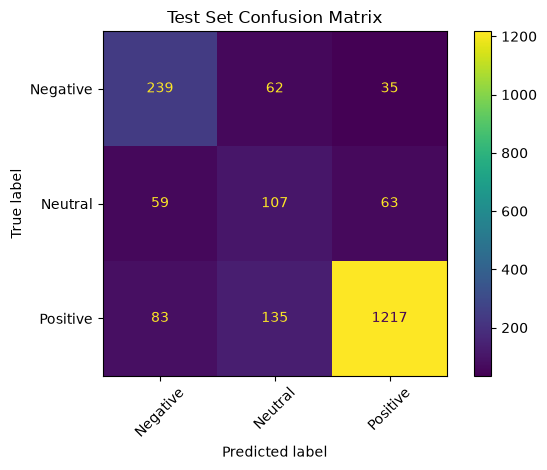

In [1]:
from pathlib import Path
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_recall_fscore_support,
    ConfusionMatrixDisplay
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

test_df = pd.read_csv(ROOT / "data" / "processed" / "test.csv")

# Load best traditional ML model
model = joblib.load(
    ROOT / "models" / "traditional_ml" / "best_tfidf_model.joblib"
)

ml_predictions = model.predict(test_df["clean_text"])

ml_acc = accuracy_score(test_df["sentiment"], ml_predictions)
ml_p, ml_r, ml_f1, _ = precision_recall_fscore_support(
    test_df["sentiment"], ml_predictions, average="macro", zero_division=0
)

print("=== Traditional ML (Tuned Linear SVM) Test Results ===")
print(f"Test Accuracy:   {ml_acc:.4f}")
print(f"Macro Precision: {ml_p:.4f}")
print(f"Macro Recall:    {ml_r:.4f}")
print(f"Macro F1:        {ml_f1:.4f}")
print("\nClassification Report:")
print(classification_report(
    test_df["sentiment"],
    ml_predictions,
    zero_division=0
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    test_df["sentiment"],
    ml_predictions,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)
plt.title("Traditional ML - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.preprocessing import LabelEncoder

bert_dir = ROOT / "models" / "bert" / "fine-tuned"

if bert_dir.exists():
    train_df = pd.read_csv(ROOT / "data" / "processed" / "train.csv")
    encoder = LabelEncoder()
    encoder.fit(train_df["sentiment"])
    y_test = encoder.transform(test_df["sentiment"])

    tokenizer = AutoTokenizer.from_pretrained(str(bert_dir))
    bert_model = AutoModelForSequenceClassification.from_pretrained(str(bert_dir))
    device = "cuda" if torch.cuda.is_available() else "cpu"
    bert_model.to(device)
    bert_model.eval()

    bert_preds = []
    batch_size = 32
    with torch.no_grad():
        for i in range(0, len(test_df), batch_size):
            batch_texts = test_df["review_text"].iloc[i:i+batch_size].tolist()
            inputs = tokenizer(batch_texts, padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
            outputs = bert_model(**inputs)
            preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
            bert_preds.extend(preds)

    bert_preds = np.array(bert_preds)
    bert_pred_labels = encoder.inverse_transform(bert_preds)

    bert_acc = accuracy_score(y_test, bert_preds)
    bert_p, bert_r, bert_f1, _ = precision_recall_fscore_support(
        y_test, bert_preds, average="macro", zero_division=0
    )

    print("=== Fine-Tuned BERT Test Results ===")
    print(f"Test Accuracy:   {bert_acc:.4f}")
    print(f"Macro Precision: {bert_p:.4f}")
    print(f"Macro Recall:    {bert_r:.4f}")
    print(f"Macro F1:        {bert_f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, bert_preds, target_names=encoder.classes_))

    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        test_df["sentiment"],
        bert_pred_labels,
        xticks_rotation=45,
        cmap="Greens",
        ax=ax
    )
    plt.title("Fine-Tuned BERT - Test Set Confusion Matrix")
    plt.tight_layout()
    plt.show()
else:
    print("BERT fine-tuned model directory not found.")


In [ ]:
# Model Comparison Summary Table
comparison_data = [
    {
        "Model": "Traditional ML (Tuned Linear SVM)",
        "Accuracy": ml_acc,
        "Macro Precision": ml_p,
        "Macro Recall": ml_r,
        "Macro F1": ml_f1
    }
]

if "bert_acc" in locals():
    comparison_data.append({
        "Model": "Fine-Tuned BERT",
        "Accuracy": bert_acc,
        "Macro Precision": bert_p,
        "Macro Recall": bert_r,
        "Macro F1": bert_f1
    })

comparison_df = pd.DataFrame(comparison_data).sort_values("Accuracy", ascending=False)
display(comparison_df)

eval_dir = ROOT / "outputs" / "evaluation"
eval_dir.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(eval_dir / "final_model_comparison.csv", index=False)
print("Saved comparison results to outputs/evaluation/final_model_comparison.csv")
